# Лабораторна робота №2

## Тема роботи

Паралельна обробка наборів даних із використанням multiprocessing.

## Мета роботи

Виконати аналіз Online Retail II, правильно об'єднати часткові агрегати та виміряти практичну доцільність багатопроцесорного підходу.

## Завдання

Виконати всі 15 завдань методички на вихідному CSV: підготувати продажі, розрахувати агрегати, групування та Top-10, порівняти послідовну обробку й пул із 1/2/4/8 процесів.

## Теоретичні відомості

`Pool.starmap()` передає кожній worker-функції DataFrame і назви стовпців. У Windows використано `spawn` та захищену точку входу.

Суми й кількості адитивні; мінімум і максимум об'єднуються відповідними операціями. Загальне середнє обчислюється як Σsum/Σcount, а середнє кожної країни — як сума виручки цієї країни, поділена на кількість її рядків. Середні частин без зважування не усереднюються.



## Використані технології та підготовка середовища

Python, pandas, NumPy, Matplotlib та засоби паралельності з модуля роботи. Встановлення: `python -m pip install -r requirements.txt`. Повні обчислення: `python -m lab02.main`. Notebook відтворює аналіз збереженого повного експерименту; worker-функції розміщені в імпортованих `.py`, а запуск пулів відбувається через CLI.

In [1]:
from pathlib import Path
import sys
import json
import inspect
import random
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

root = Path.cwd().resolve()
if not (root / "common").exists():
    root = root.parent
if not (root / "common").exists():
    raise RuntimeError("Відкрийте notebook у корені проєкту або каталозі лабораторної.")
sys.path.insert(0, str(root))
from lab02 import algorithms as a

result_dir = root / "lab02" / "results"


def read_json(name):
    return json.loads((result_dir / name).read_text(encoding="utf-8"))


meta = read_json("metadata.json")
timings = pd.read_csv(result_dir / "timings.csv")
raw = pd.read_csv(result_dir / "timings_raw.csv")
pd.set_option("display.max_columns", 16)
assert not meta.get("quick", False), "Для захисту потрібен повний запуск."

## 1. Завантаження

Вихідні дані та відбиток файлу.

In [2]:
display(meta["dataset"])
display(read_json("profile.json"))

{'filename': 'online_retail_II.csv',
 'bytes': 94850204,
 'sha256': '32569a66f3842a82b0d8c4d63b263c5d98a76bde5d1f65c6c01bf457e541d3a9'}

{'rows': 1067371,
 'columns': 8,
 'source_columns': ['Invoice',
  'StockCode',
  'Description',
  'Quantity',
  'InvoiceDate',
  'Price',
  'Customer ID',
  'Country'],
 'source_dtypes': {'Invoice': 'object',
  'StockCode': 'object',
  'Description': 'object',
  'Quantity': 'int64',
  'InvoiceDate': 'object',
  'Price': 'float64',
  'Customer ID': 'float64',
  'Country': 'object'},
 'missing': {'Invoice': 0,
  'StockCode': 0,
  'Description': 4382,
  'Quantity': 0,
  'InvoiceDate': 0,
  'Price': 0,
  'Customer ID': 243007,
  'Country': 0},
 'duplicates': 34335,
 'encoding': 'utf-8-sig',
 'separator': ',',
 'limited': False}

## 2. Первинний аналіз

Розмір, типи, пропуски та дублікати.

In [3]:
p = read_json("profile.json")
display(pd.DataFrame({"Тип": p["source_dtypes"], "Пропуски": p["missing"]}))
display({"rows": p["rows"], "columns": p["columns"], "duplicates": p["duplicates"]})

,Тип,Пропуски
Invoice,object,0
StockCode,object,0
Description,object,4382
Quantity,int64,0
InvoiceDate,object,0
Price,float64,0
Customer ID,float64,243007
Country,object,0


{'rows': 1067371, 'columns': 8, 'duplicates': 34335}

## 3. Підготовка

Взаємовиключні причини очищення; анонімні продажі збережено.

In [4]:
cleaning = read_json("cleaning.json")
display(cleaning)
assert sum(cleaning["excluded"].values()) + cleaning["after"] == cleaning["before"]

{'before': 1067371,
 'excluded': {'exact_duplicates': 34335,
  'cancelled': 19104,
  'missing_required': 4275,
  'invalid_quantity': 760,
  'invalid_price': 984,
  'invalid_revenue': 0},
 'diagnostics': {'cancelled': 19494,
  'nonpositive_quantity': 22950,
  'nonpositive_price': 6207,
  'missing_customers': 243007,
  'numeric_description': {'Quantity': {'count': 1067371.0,
    'mean': 9.9388984711033,
    'std': 172.70579407675342,
    'min': -80995.0,
    '25%': 1.0,
    '50%': 3.0,
    '75%': 10.0,
    'max': 80995.0},
   'UnitPrice': {'count': 1067371.0,
    'mean': 4.649387727416239,
    'std': 123.5530587214632,
    'min': -53594.36,
    '25%': 1.25,
    '50%': 2.1,
    '75%': 4.15,
    'max': 38970.0}}},
 'after': 1007913,
 'removed': 59458,
 'retained_missing_customers': 228488,
 'date_min': '2009-12-01T07:45:00',
 'date_max': '2011-12-09T12:50:00'}

## 4. Revenue

Перші підготовлені рядки та контроль добутку.

In [5]:
sample = pd.read_csv(result_dir / "prepared_sample.csv")
display(sample)
assert np.allclose(sample.Revenue, sample.Quantity * sample.UnitPrice)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085,United Kingdom,39.6
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085,United Kingdom,59.5
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085,United Kingdom,30.6
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085,United Kingdom,45.0


## 5. Фільтрація

Використано глобальний поріг середнього Revenue.

In [6]:
display(read_json("filter.json"))

{'threshold': 20.315503865909058,
 'count': 191092,
 'percentage': 18.959176039995516,
 'revenue': 13540604.950000001,
 'base_count': 1007913}

## 6. Групування

Повна таблиця країн.

In [7]:
countries = pd.read_csv(result_dir / "countries.csv")
display(countries)

,Country,count,total,mean
0,Australia,1789,1.692835e+05,94.624628
1,Austria,922,2.361301e+04,25.610640
2,Bahrain,124,3.109790e+03,25.078952
3,Belgium,3055,6.538782e+04,21.403542
4,Bermuda,34,1.253140e+03,36.857059
5,Brazil,94,1.411870e+03,15.019894
6,Canada,228,4.883040e+03,21.416842
7,Channel Islands,1551,4.462333e+04,28.770683
8,Cyprus,1136,2.484995e+04,21.874956
9,Czech Republic,25,8.267400e+02,33.069600


## 7. Top-10

Сортування за виручкою.

,Country,count,total,mean
0,United Kingdom,926038,1.741020e+07,18.800736
1,EIRE,17154,6.587673e+05,38.403131
2,Netherlands,5085,5.540381e+05,108.955377
3,Germany,16432,4.250197e+05,25.865367
4,France,13639,3.504561e+05,25.695146
5,Australia,1789,1.692835e+05,94.624628
6,Spain,3662,1.083325e+05,29.582875
7,Switzerland,3122,1.006856e+05,32.250349
8,Sweden,1336,9.186982e+04,68.764835
9,Denmark,778,6.858069e+04,88.149987


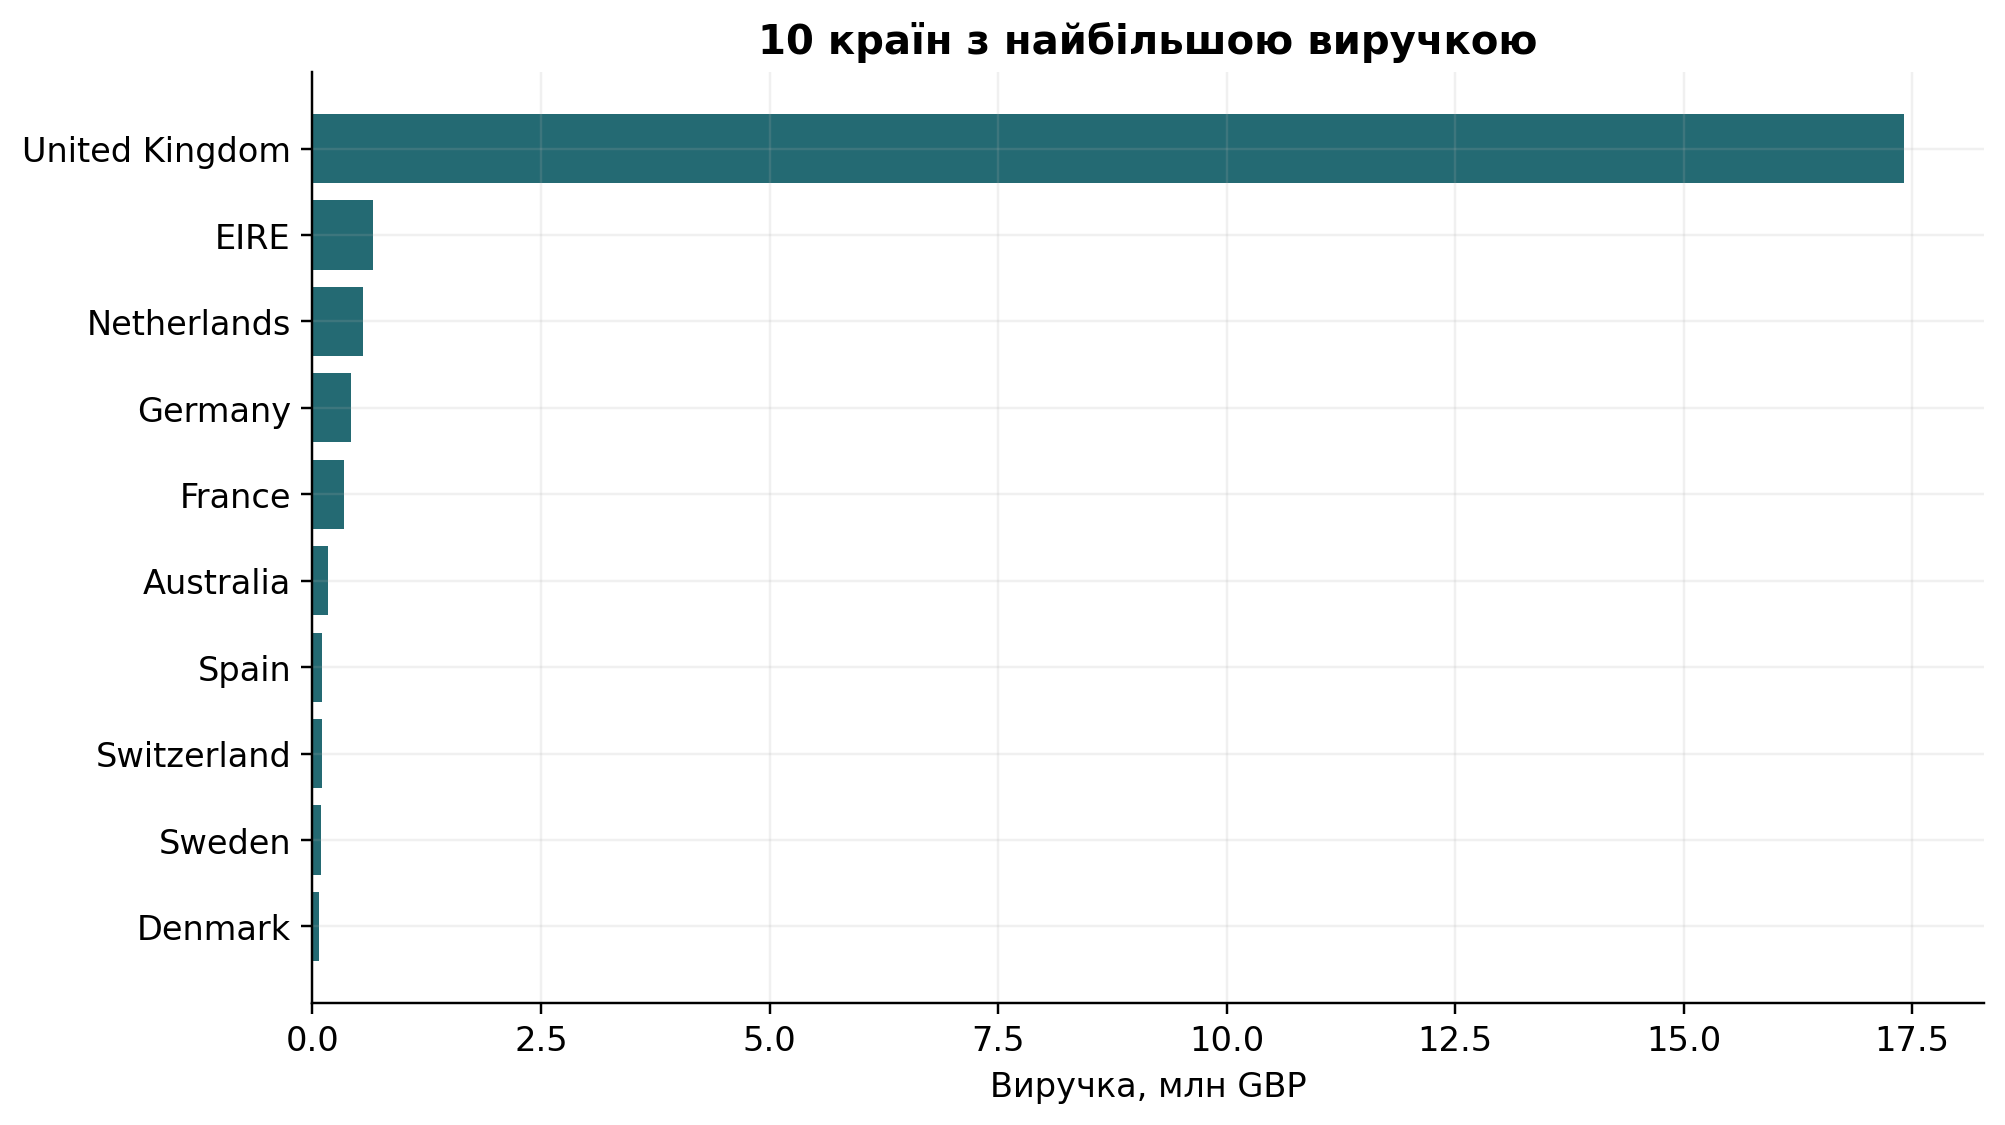

In [8]:
display(pd.read_csv(result_dir / "top10.csv"))
display(Image(filename=str(result_dir / "top10.png")))

## 8. Функція та послідовний алгоритм

Глобальні статистики та реалізація.

In [9]:
print(inspect.getsource(a.process_chunk))
display(read_json("statistics.json"))
display(raw[raw.method == "sequential"])

def process_chunk(
    frame: pd.DataFrame, value_column: str = "Revenue", group_column: str = "Country"
) -> ChunkStats:
    values = frame[value_column]
    if values.isna().any() or frame[group_column].isna().any():
        raise ValueError("Агрегація потребує очищених значень та груп.")
    count, total = len(frame), float(values.sum())
    groups = (
        frame.groupby(group_column, sort=True)[value_column]
        .agg(count="size", total="sum", mean="mean")
        .reset_index()
    )
    return ChunkStats(
        count,
        total,
        total / count if count else None,
        float(values.min()) if count else None,
        float(values.max()) if count else None,
        groups,
    )



{'count': 1007913,
 'total': 20476260.447999995,
 'mean': 20.315503865909058,
 'minimum': 0.001,
 'maximum': 168469.6}

,workload,method,workers,effective_workers,repeat,seconds,verified
0,retail,sequential,1,1,1,0.139889,True
5,retail,sequential,1,1,2,0.129216,True
10,retail,sequential,1,1,3,0.130023,True


## 9. Розподіл DataFrame

Нерівні частини не порушують загальне середнє.

In [10]:
from common.utilities import split_frame

parts = split_frame(sample, 4)
display([len(part) for part in parts])
assert sum(map(len, parts)) == len(sample)

[3, 3, 2, 2]

## 10. Pool та starmap

Запуск із CLI гарантує імпортовані worker-функції.

In [11]:
print(inspect.getsource(a.parallel_processing))

def parallel_processing(frame: pd.DataFrame, workers: int) -> ChunkStats:
    if workers < 1:
        raise ValueError("Кількість процесів має бути додатною.")
    # Передається весь очищений DataFrame, без приховування вартості pickle.
    chunks = split_frame(frame, workers)
    with mp.get_context("spawn").Pool(processes=workers) as pool:
        results = pool.starmap(
            process_chunk, [(chunk, "Revenue", "Country") for chunk in chunks]
        )
    return merge_results(results)



## 11. Об'єднання

Коректність зважування на нерівних частинах.

In [12]:
print(inspect.getsource(a.merge_results))
merged = a.merge_results([a.process_chunk(part) for part in parts])
a.assert_equivalent(a.process_chunk(sample), merged)
display(merged.scalar_dict())

def merge_results(
    results: list[ChunkStats], group_column: str = "Country"
) -> ChunkStats:
    if not results:
        raise ValueError("Потрібен щонайменше один частковий результат.")
    count = sum(result.count for result in results)
    total = math.fsum(result.total for result in results)
    nonempty = [result for result in results if result.count]
    groups = pd.concat([result.groups for result in results], ignore_index=True)
    groups = groups.groupby(group_column, as_index=False, sort=True).agg(
        count=("count", "sum"), total=("total", "sum")
    )
    groups["mean"] = groups.total / groups["count"]
    return ChunkStats(
        count,
        total,
        total / count if count else None,
        min(r.minimum for r in nonempty) if nonempty else None,
        max(r.maximum for r in nonempty) if nonempty else None,
        groups,
    )



{'count': 10,
 'total': 580.9,
 'mean': 58.089999999999996,
 'minimum': 30.0,
 'maximum': 100.8}

## 12. Перевірка

Кожен повний запуск перевірив також країни та Top-10.

In [13]:
assert raw.verified.all()
display(raw[["method", "workers", "repeat", "verified"]])

,method,workers,repeat,verified
0,sequential,1,1,True
1,multiprocessing,1,1,True
2,multiprocessing,2,1,True
3,multiprocessing,4,1,True
4,multiprocessing,8,1,True
5,sequential,1,2,True
6,multiprocessing,1,2,True
7,multiprocessing,2,2,True
8,multiprocessing,4,2,True
9,multiprocessing,8,2,True


## 13. Вимірювання

Окремі повтори та медіани для 1,2,4,8 процесів.

In [14]:
display(raw)
display(timings)

,workload,method,workers,effective_workers,repeat,seconds,verified
0,retail,sequential,1,1,1,0.139889,True
1,retail,multiprocessing,1,1,1,1.555696,True
2,retail,multiprocessing,2,2,1,1.631862,True
3,retail,multiprocessing,4,4,1,1.828847,True
4,retail,multiprocessing,8,8,1,2.145946,True
5,retail,sequential,1,1,2,0.129216,True
6,retail,multiprocessing,1,1,2,1.508770,True
7,retail,multiprocessing,2,2,2,1.622217,True
8,retail,multiprocessing,4,4,2,1.703644,True
9,retail,multiprocessing,8,8,2,2.133569,True


,workload,method,workers,effective_workers,seconds,min_seconds,max_seconds,verified,repeats,speedup,efficiency_pct
0,retail,sequential,1,1,0.130023,0.129216,0.139889,True,3,1.000000,100.000000
1,retail,multiprocessing,1,1,1.519642,1.508770,1.555696,True,3,0.085562,8.556177
2,retail,multiprocessing,2,2,1.631862,1.622217,1.726708,True,3,0.079678,3.983894
3,retail,multiprocessing,4,4,1.789092,1.703644,1.828847,True,3,0.072676,1.816890
4,retail,multiprocessing,8,8,2.145946,2.133569,2.169978,True,3,0.060590,0.757378


## 14. Графіки

Час, прискорення та ефективність.

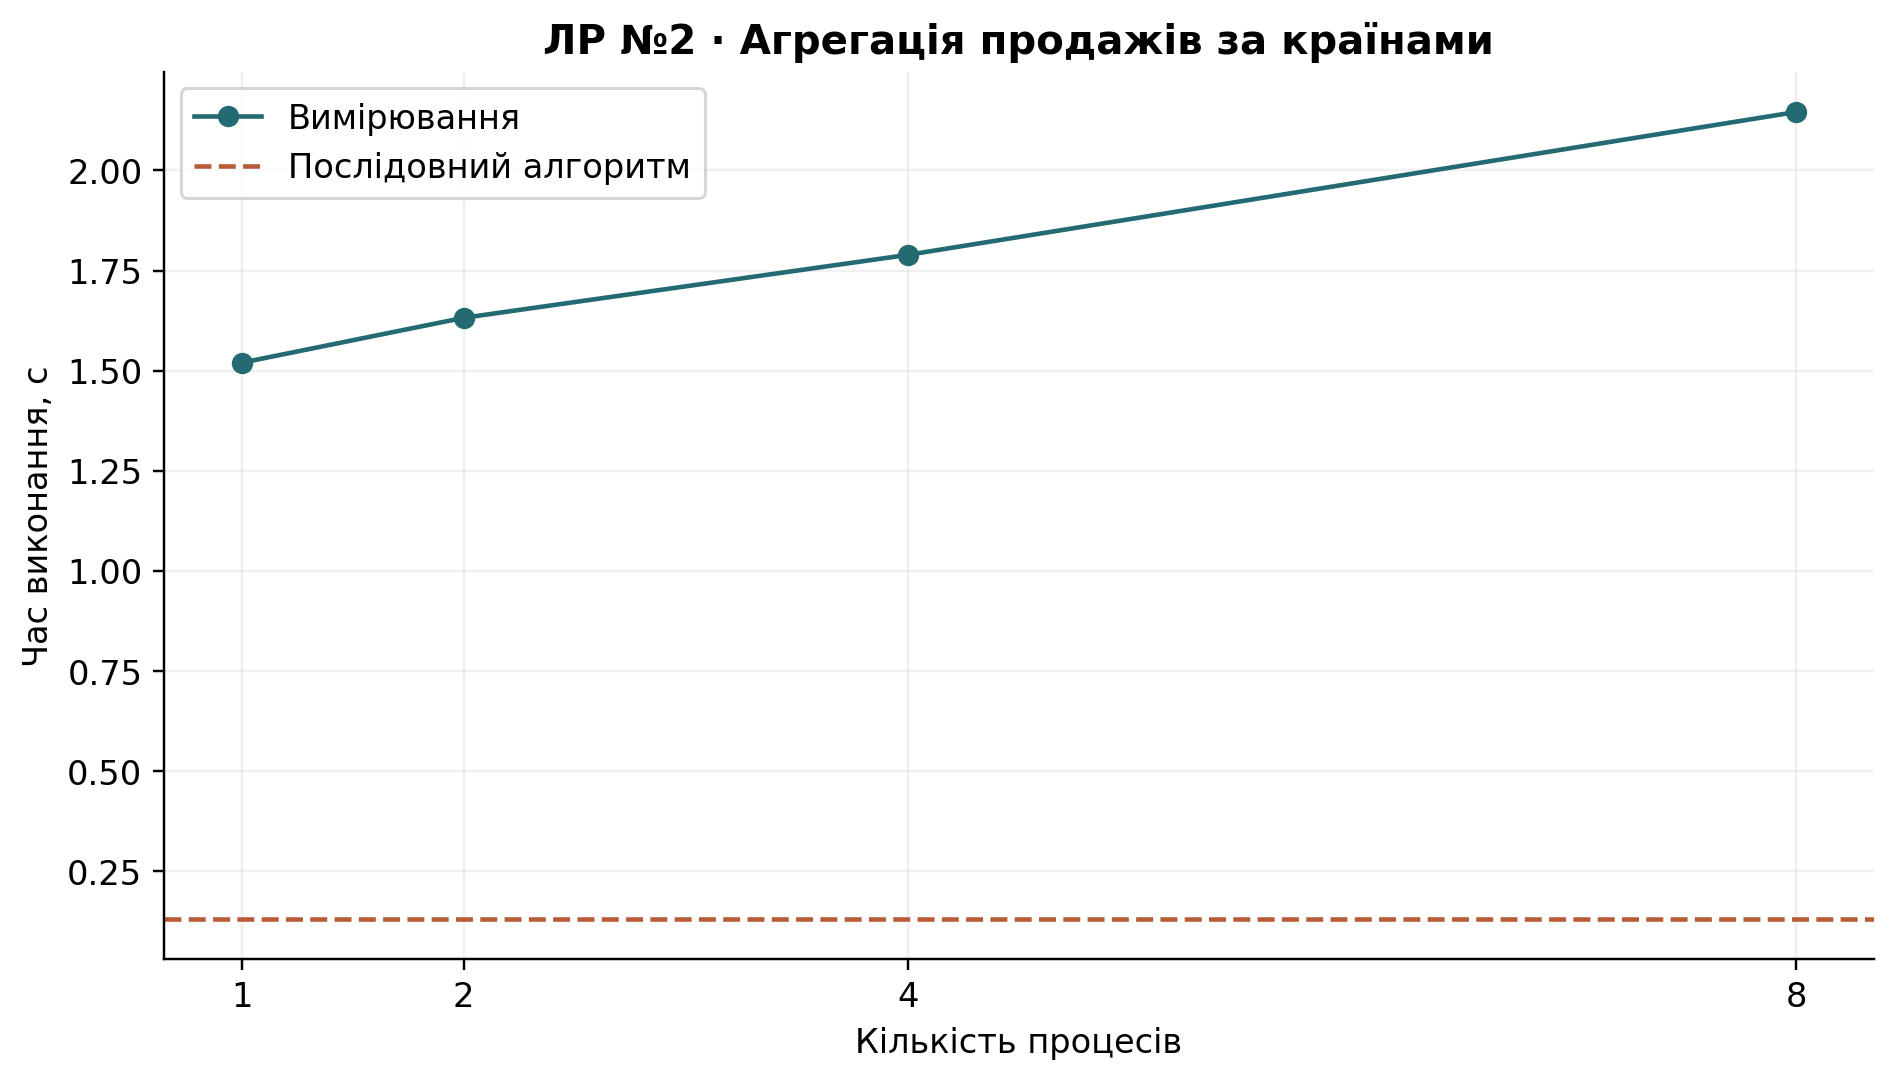

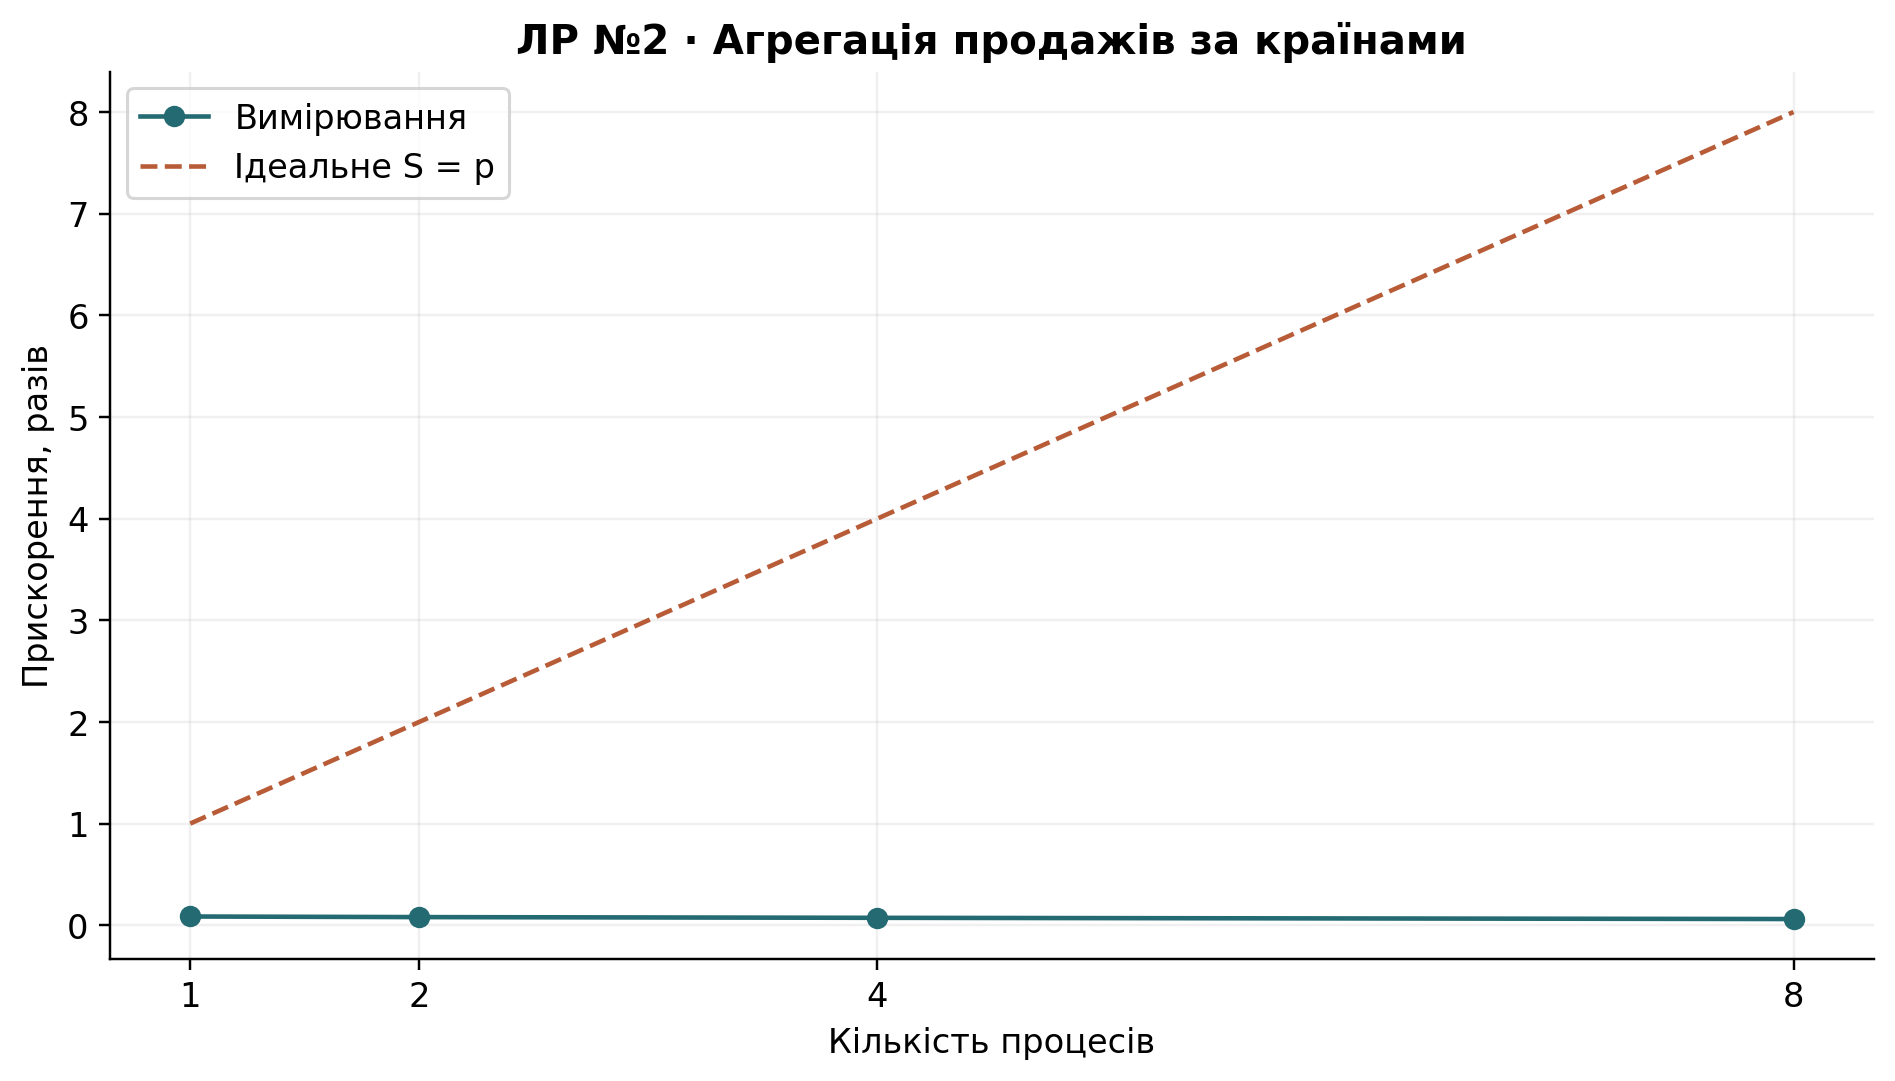

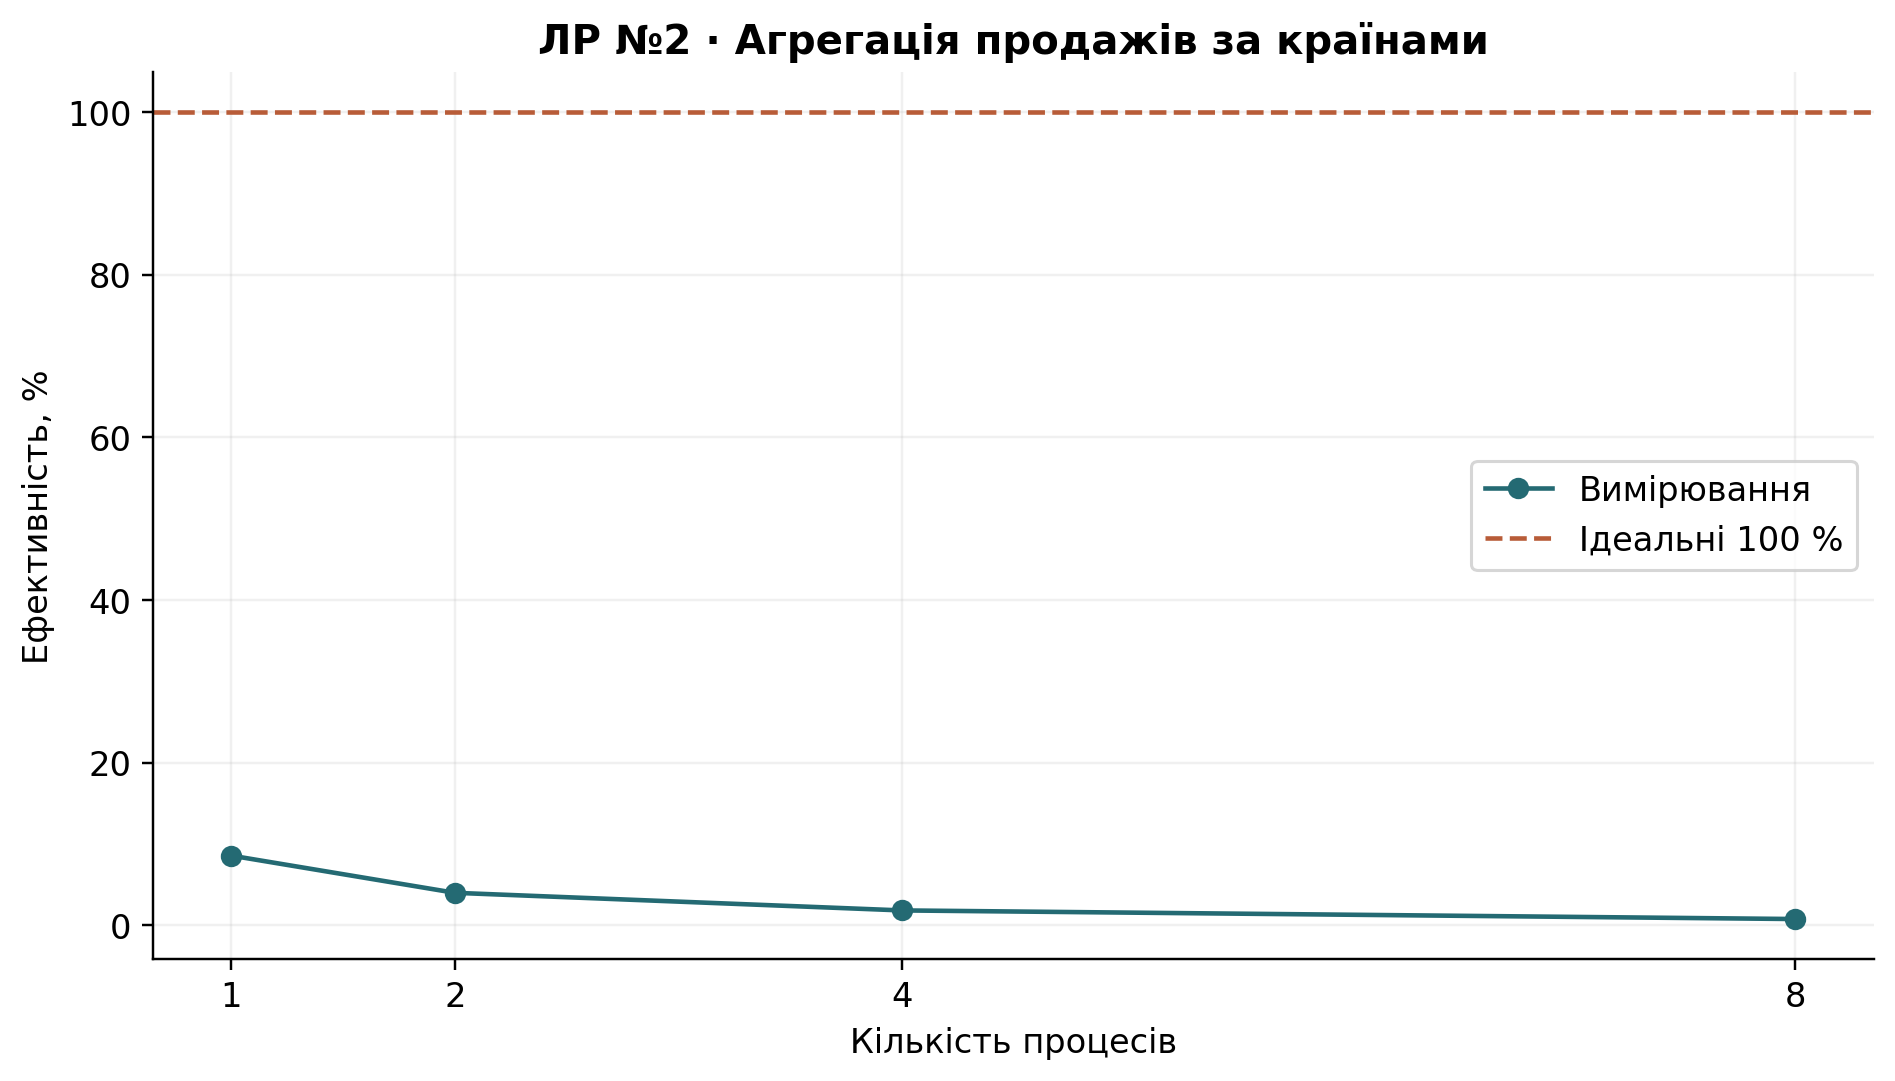

In [15]:
for name in ["time", "speedup", "efficiency"]:
    display(Image(filename=str(result_dir / f"{name}.png")))

## 15. Оптимальна кількість процесів

Найшвидший пул та baseline порівнюються окремо.

In [16]:
display(timings.sort_values("seconds"))
display(meta["environment"])

,workload,method,workers,effective_workers,seconds,min_seconds,max_seconds,verified,repeats,speedup,efficiency_pct
0,retail,sequential,1,1,0.130023,0.129216,0.139889,True,3,1.000000,100.000000
1,retail,multiprocessing,1,1,1.519642,1.508770,1.555696,True,3,0.085562,8.556177
2,retail,multiprocessing,2,2,1.631862,1.622217,1.726708,True,3,0.079678,3.983894
3,retail,multiprocessing,4,4,1.789092,1.703644,1.828847,True,3,0.072676,1.816890
4,retail,multiprocessing,8,8,2.145946,2.133569,2.169978,True,3,0.060590,0.757378


{'python': '3.12.6',
 'os': 'Windows-11-10.0.26200-SP0',
 'logical_cpus': 16,
 'libraries': {'numpy': '2.1.3',
  'pandas': '2.2.3',
  'matplotlib': '3.9.2',
  'pyspark': '4.0.3',
  'nbformat': '5.11.1',
  'pytest': '9.0.3'}}

## Аналіз результатів

Вихідний набір: 1,067,371 рядків і 8 стовпців. Точних дублікатів: 34,335. Після очищення: 1,007,913; виключено 59,458.

| Причина          |   Виключено |
|:-----------------|------------:|
| exact_duplicates |       34335 |
| cancelled        |       19104 |
| missing_required |        4275 |
| invalid_quantity |         760 |
| invalid_price    |         984 |
| invalid_revenue  |           0 |

Збережено 228,488 продажів без відомого клієнта. Глобальне середнє Revenue: 20.315504 GBP; вище нього 191,092 рядків (18.959%), сума 13,540,604.95 GBP.

### Top-10 країн

| Country        |   count |         total |     mean |
|:---------------|--------:|--------------:|---------:|
| United Kingdom |  926038 | 17410196.1170 |  18.8007 |
| EIRE           |   17154 |   658767.3100 |  38.4031 |
| Netherlands    |    5085 |   554038.0900 | 108.9554 |
| Germany        |   16432 |   425019.7110 |  25.8654 |
| France         |   13639 |   350456.0900 |  25.6951 |
| Australia      |    1789 |   169283.4600 |  94.6246 |
| Spain          |    3662 |   108332.4900 |  29.5829 |
| Switzerland    |    3122 |   100685.5900 |  32.2503 |
| Sweden         |    1336 |    91869.8200 |  68.7648 |
| Denmark        |     778 |    68580.6900 |  88.1500 |

Послідовне векторизоване групування: 0.1300 с. Найшвидший пул: p=1, 1.5196 с, S=0.0856, E=8.56%. Найбільша ефективність серед пулів при p=1. Жоден досліджений пул не перевершив послідовний алгоритм. Саме групування pandas реалізоване ефективними низькорівневими операціями. Запуск процесів і серіалізація понад мільйона вихідних рядків можуть коштувати більше, ніж корисні обчислення. Це пояснює відмінність від CPU-циклу в ЛР №1. Збільшення p збільшує витрати пам'яті та організації пулу. Для цього аналізу доцільний спосіб з найменшим виміряним часом; оптимум пулу не означає, що слід обов'язково обрати multiprocessing. Послідовний і паралельний алгоритми дають однакові числові результати в установленій похибці, усі групи та Top-10 збігаються.

In [17]:
display(timings)

,workload,method,workers,effective_workers,seconds,min_seconds,max_seconds,verified,repeats,speedup,efficiency_pct
0,retail,sequential,1,1,0.130023,0.129216,0.139889,True,3,1.000000,100.000000
1,retail,multiprocessing,1,1,1.519642,1.508770,1.555696,True,3,0.085562,8.556177
2,retail,multiprocessing,2,2,1.631862,1.622217,1.726708,True,3,0.079678,3.983894
3,retail,multiprocessing,4,4,1.789092,1.703644,1.828847,True,3,0.072676,1.816890
4,retail,multiprocessing,8,8,2.145946,2.133569,2.169978,True,3,0.060590,0.757378


## Висновки

Найменший час має sequential, p=1: 0.1300 с. Правильність усіх повних запусків підтверджено; доцільність паралельності визначається співвідношенням обчислень і накладних витрат.